# Random Forest — tuning, evaluation and test on 4 targets
Targets: **Cath** (overall CAD), **LAD**, **LCX**, **RCA**. Input: `data/processed/cad_clean.csv` produced by notebook 01 (frozen 80/20 stratified split).

Workflow: baseline → complexity / depth sweeps → feature-count sweep → GridSearchCV → RandomizedSearchCV → CV-fold study → nested CV (paper-comparable protocol) → threshold tuning → **single** test evaluation → paper methods (single / OR-rule / stacked) → permutation importance → save.

All scaling, encoding, feature selection and SMOTE sit inside one `imblearn` `Pipeline`, so every CV fold is leak-free. LAD/LCX/RCA/Cath are never inputs, except as *out-of-fold* probabilities in the paper's stacked method.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, cross_validate, cross_val_predict, validation_curve)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score, f1_score, recall_score,
                             precision_score, brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve, make_scorer, ConfusionMatrixDisplay)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
pd.set_option('display.width',220,'display.max_columns',60,'display.max_rows',200)
sns.set_theme(style='whitegrid'); SEED=42; M='rf'
ROOT=Path('..').resolve(); OUT=ROOT/'data'/'processed'; RES=ROOT/'results'; FIG=RES/'figures'; MOD=ROOT/'models'
for p in (RES,FIG,MOD): p.mkdir(parents=True,exist_ok=True)

## 1. Load the cleaned data and rebuild the same split

In [2]:
df = pd.read_csv(OUT/'cad_clean.csv', keep_default_na=False)
TARGETS=['Cath','LAD','LCX','RCA']; AUDIT=['Cath_original','label_corrected','n_vessels']
FEATURES=[c for c in df.columns if c not in ['patient_idx','split']+TARGETS+AUDIT]
assert not set(FEATURES)&set(TARGETS+AUDIT)
tr=df[df.split=='train']; te=df[df.split=='test']
X_tr,X_te,X_all=tr[FEATURES],te[FEATURES],df[FEATURES]
Y_tr={t:tr[t].values for t in TARGETS}; Y_te={t:te[t].values for t in TARGETS}; Y_all={t:df[t].values for t in TARGETS}
print(len(FEATURES),'features | train',X_tr.shape,'| test',X_te.shape)
pd.DataFrame({'train_pos_rate':[Y_tr[t].mean() for t in TARGETS],'test_pos_rate':[Y_te[t].mean() for t in TARGETS]},index=TARGETS).round(3)

62 features | train (242, 62) | test (61, 62)


,train_pos_rate,test_pos_rate
Cath,0.715,0.721
LAD,0.583,0.590
LCX,0.388,0.410
RCA,0.376,0.377


## 2. Preprocessing definition (identical to notebook 01)

In [3]:
num_cols=['Age','Weight','Length','BMI','BP','PR','FBS','CR','TG','LDL','HDL','BUN','ESR','HB','K','Na','WBC','Lymph','Neut','PLT','EF-TTE']
skew_cols=['FBS','TG','ESR','WBC','PLT','CR','TG_HDL','NLR','LDL_HDL']
scale_cols=[c for c in num_cols if c in FEATURES and c not in skew_cols]+['pulse_pressure_proxy','risk_factor_count','ecg_abnormal_count','symptom_score']
ordinal_cols=['VHD','Function Class','Region RWMA']; nominal_cols=['BBB','CP_type','age_group']
binary_cols=[c for c in FEATURES if c not in skew_cols+scale_cols+ordinal_cols+nominal_cols]
assert sorted(skew_cols+scale_cols+ordinal_cols+nominal_cols+binary_cols)==sorted(FEATURES)
def build_preprocessor():
    return ColumnTransformer([
        ('skew',Pipeline([('log',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),('sc',StandardScaler())]),skew_cols),
        ('num',StandardScaler(),scale_cols),
        ('ord',Pipeline([('enc',OrdinalEncoder(categories=[['N','mild','Moderate','Severe'],[0,1,2,3],[0,1,2,3,4]])),('sc',StandardScaler())]),ordinal_cols),
        ('nom',OneHotEncoder(handle_unknown='ignore',sparse_output=False),nominal_cols),
        ('bin','passthrough',binary_cols)],verbose_feature_names_out=False)
# the explicit fit / fit_transform / transform sequence on this split
_p=build_preprocessor(); _a=_p.fit_transform(X_tr); _b=_p.transform(X_te)
print('fit_transform(train):',_a.shape,'| transform(test):',_b.shape)

fit_transform(train): (242, 70) | transform(test): (61, 70)


## 3. Pipeline factory, CV schemes, metric helpers

In [4]:
def make_pipe(clf):
    # prep -> univariate feature selection (k tunable, 'all' = off) -> sampler (tunable: passthrough | SMOTE) -> classifier
    return ImbPipeline([('prep',build_preprocessor()),('fs',SelectKBest(f_classif,k='all')),('sampler','passthrough'),('clf',clf)])
def new_clf(): return RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1)
cv5  = StratifiedKFold(5,shuffle=True,random_state=SEED)
cv52 = RepeatedStratifiedKFold(n_splits=5,n_repeats=2,random_state=SEED)
SCORING={'roc_auc':'roc_auc','average_precision':'average_precision','balanced_accuracy':'balanced_accuracy','f1':'f1','recall':'recall'}
spw={t:float((Y_tr[t]==0).sum()/(Y_tr[t]==1).sum()) for t in TARGETS}      # neg/pos ratio for scale_pos_weight
print({k:round(v,2) for k,v in spw.items()})

{'Cath': 0.4, 'LAD': 0.72, 'LCX': 1.57, 'RCA': 1.66}


In [5]:
def metrics_at(y,p,thr):
    yh=(p>=thr).astype(int); tn,fp,fn,tp=confusion_matrix(y,yh,labels=[0,1]).ravel()
    sens=tp/(tp+fn) if tp+fn else np.nan; spec=tn/(tn+fp) if tn+fp else np.nan
    return dict(threshold=float(thr),accuracy=accuracy_score(y,yh),balanced_acc=(sens+spec)/2,sensitivity=sens,specificity=spec,
                precision=precision_score(y,yh,zero_division=0),f1=f1_score(y,yh,zero_division=0),roc_auc=roc_auc_score(y,p),
                pr_auc=average_precision_score(y,p),brier=brier_score_loss(y,p),TP=tp,FP=fp,TN=tn,FN=fn)
def thr_youden(y,p):
    f,t,th=roc_curve(y,p); return float(th[np.argmax(t-f)])
def thr_sens(y,p,s=0.95):
    f,t,th=roc_curve(y,p); return float(th[np.where(t>=s)[0][0]])       # highest threshold reaching sensitivity s (max specificity)
def boot_ci(y,p,thr,B=1000,seed=SEED):
    rng=np.random.default_rng(seed); a,b=[],[]
    for _ in range(B):
        i=rng.integers(0,len(y),len(y))
        if len(set(y[i]))<2: continue
        a.append(roc_auc_score(y[i],p[i])); b.append(accuracy_score(y[i],(p[i]>=thr).astype(int)))
    return np.percentile(a,[2.5,97.5]),np.percentile(b,[2.5,97.5])

## 4. Baselines: Dummy vs default model (5-fold × 2 repeats, train only)

In [6]:
def cv_row(est,t,cv=cv52):
    r=cross_validate(est,X_tr,Y_tr[t],cv=cv,scoring=SCORING,n_jobs=-1)
    return {k.replace('test_',''):v.mean() for k,v in r.items() if k.startswith('test_')}
rows=[]
for t in TARGETS:
    rows.append({'target':t,'model':'Dummy',**cv_row(make_pipe(DummyClassifier(strategy='prior')),t)})
    rows.append({'target':t,'model':'default '+M,**cv_row(make_pipe(new_clf()),t)})
baseline=pd.DataFrame(rows).set_index(['target','model']).round(3); baseline

roc_auc  average_precision  balanced_accuracy     f1  recall
target model                                                                   
Cath   Dummy         0.500              0.715              0.500  0.834   1.000
       default rf    0.929              0.971              0.821  0.911   0.933
LAD    Dummy         0.500              0.583              0.500  0.736   1.000
       default rf    0.862              0.893              0.790  0.842   0.887
LCX    Dummy         0.500              0.388              0.500  0.000   0.000
       default rf    0.713              0.591              0.587  0.419   0.346
RCA    Dummy         0.500              0.376              0.500  0.000   0.000
       default rf    0.735              0.599              0.614  0.466   0.390

## 5. Complexity / depth sweeps (train vs CV ROC-AUC)

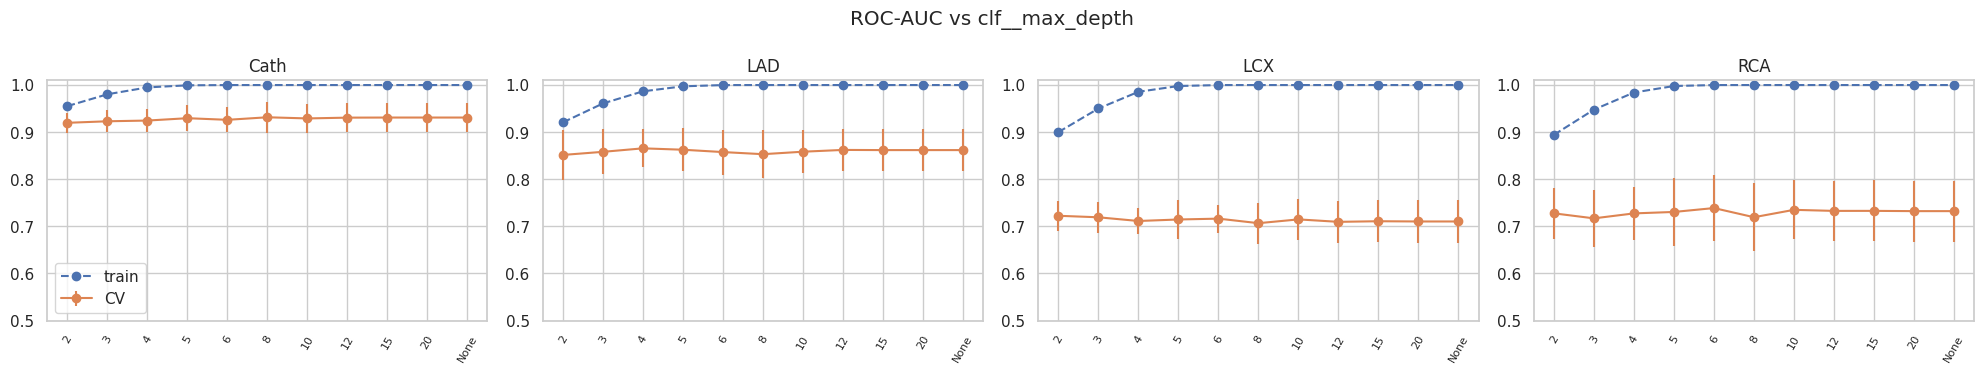

In [7]:
def sweep(param,values,title,fname):
    fig,axes=plt.subplots(1,4,figsize=(20,3.8)); out={}
    for ax,t in zip(axes,TARGETS):
        tr_s,cv_s=validation_curve(make_pipe(new_clf()),X_tr,Y_tr[t],param_name=param,param_range=values,cv=cv5,scoring='roc_auc',n_jobs=-1)
        xs=np.arange(len(values)); out[t]=pd.DataFrame({'value':[str(v) for v in values],'train_auc':tr_s.mean(1),'cv_auc':cv_s.mean(1),'cv_std':cv_s.std(1)})
        ax.plot(xs,tr_s.mean(1),'o--',label='train'); ax.errorbar(xs,cv_s.mean(1),cv_s.std(1),fmt='o-',label='CV')
        ax.set_xticks(xs); ax.set_xticklabels([str(v) for v in values],rotation=60,fontsize=8); ax.set_title(f'{t}'); ax.set_ylim(0.5,1.01)
    axes[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG/f'rf_{fname}.png',dpi=110); plt.show(); return out
p1,v1=('clf__max_depth', [2,3,4,5,6,8,10,12,15,20,None])
sw1=sweep(p1,v1,f'ROC-AUC vs {p1}','sweep1')

In [8]:
pd.concat({t:sw1[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
2         0.955  0.920     0.921  0.852     0.900  0.722     0.894  0.728
3         0.980  0.923     0.961  0.858     0.950  0.719     0.948  0.717
4         0.995  0.925     0.987  0.866     0.986  0.711     0.984  0.728
5         0.999  0.930     0.997  0.863     0.998  0.715     0.998  0.731
6         1.000  0.926     1.000  0.858     1.000  0.716     1.000  0.739
8         1.000  0.932     1.000  0.853     1.000  0.707     1.000  0.719
10        1.000  0.929     1.000  0.858     1.000  0.715     1.000  0.735
12        1.000  0.931     1.000  0.862     1.000  0.710     1.000  0.733
15        1.000  0.931     1.000  0.862     1.000  0.711     1.000  0.733
20        1.000  0.931     1.000  0.862     1.000  0.710     1.000  0.732
None      1.000  0.931     1.000  0.862     1.000  0.710     1.000  0.732

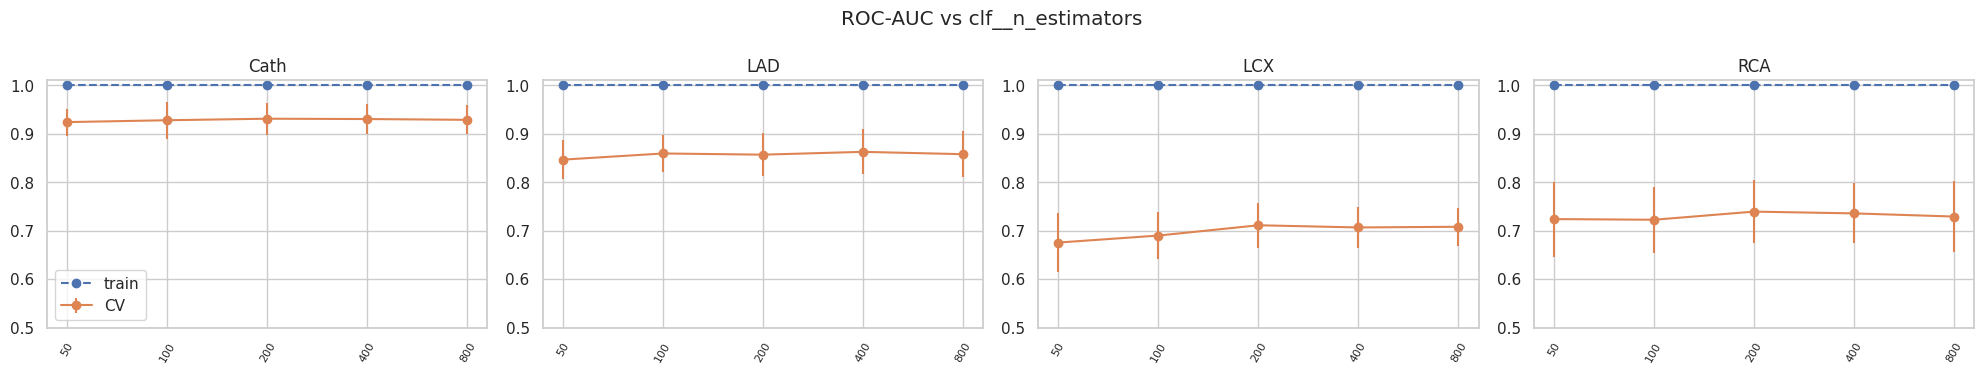

In [9]:
p2,v2=('clf__n_estimators', [50,100,200,400,800])
sw2=sweep(p2,v2,f'ROC-AUC vs {p2}','sweep2')

In [10]:
pd.concat({t:sw2[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
50          1.0  0.924       1.0  0.846       1.0  0.675       1.0  0.724
100         1.0  0.928       1.0  0.859       1.0  0.690       1.0  0.722
200         1.0  0.931       1.0  0.857       1.0  0.711       1.0  0.739
400         1.0  0.930       1.0  0.862       1.0  0.706       1.0  0.735
800         1.0  0.929       1.0  0.858       1.0  0.708       1.0  0.729

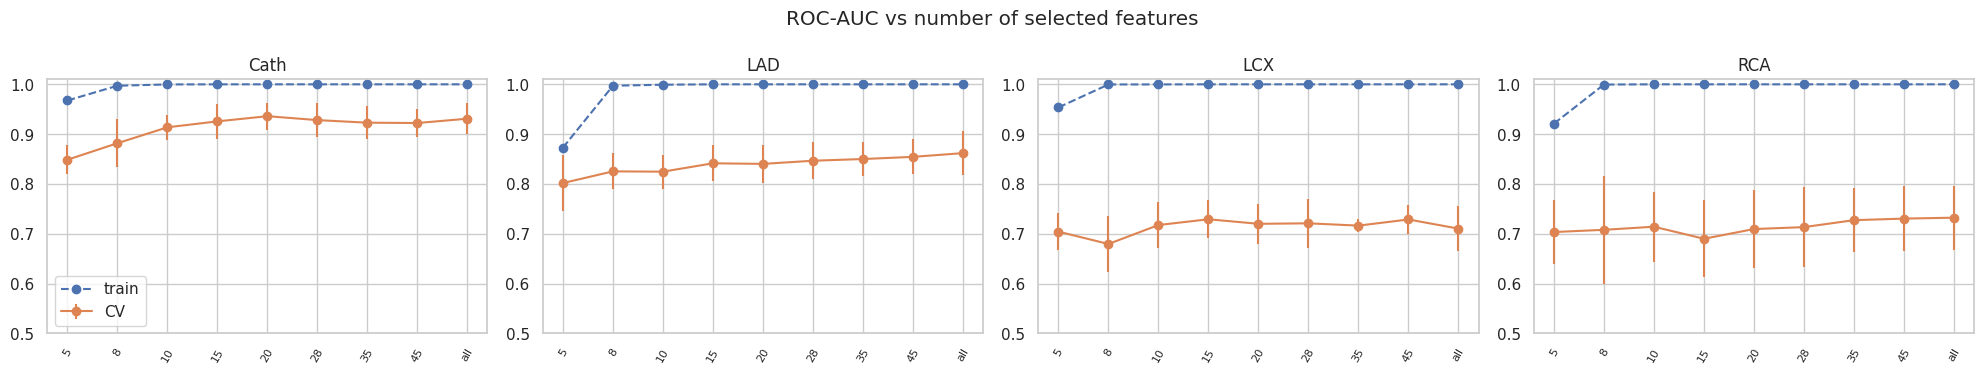

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
5         0.968  0.849     0.873  0.802     0.954  0.704     0.921  0.704
8         0.997  0.882     0.997  0.825     1.000  0.680     1.000  0.708
10        1.000  0.914     0.999  0.825     1.000  0.718     1.000  0.714
15        1.000  0.926     1.000  0.842     1.000  0.729     1.000  0.690
20        1.000  0.936     1.000  0.840     1.000  0.720     1.000  0.710
28        1.000  0.928     1.000  0.847     1.000  0.721     1.000  0.713
35        1.000  0.923     1.000  0.850     1.000  0.716     1.000  0.727
45        1.000  0.922     1.000  0.854     1.000  0.729     1.000  0.731
all       1.000  0.931     1.000  0.862     1.000  0.710     1.000  0.732

In [11]:
# number of selected features (SelectKBest inside the pipeline)
ks=[5,8,10,15,20,28,35,45,'all']
sw3=sweep('fs__k',ks,'ROC-AUC vs number of selected features','sweep_k')
pd.concat({t:sw3[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

## 6. GridSearchCV (focused grid, 5×2 repeated CV, 5 metrics, refit on ROC-AUC)

In [12]:
def param_grid(spw):
    return {'fs__k':[20,35,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)],'clf__n_estimators':[300],'clf__max_depth':[3,5,8,12,None],
            'clf__min_samples_leaf':[1,2,4],'clf__max_features':['sqrt','log2',0.3],'clf__class_weight':[None,'balanced_subsample']}
def param_space(spw):
    return {'fs__k':[10,15,20,28,35,45,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)],'clf__n_estimators':randint(100,800),
            'clf__max_depth':[2,3,4,5,6,8,10,12,15,20,None],'clf__min_samples_split':randint(2,20),'clf__min_samples_leaf':randint(1,10),
            'clf__max_features':['sqrt','log2',0.2,0.4,0.6],'clf__bootstrap':[True,False],'clf__criterion':['gini','entropy','log_loss'],
            'clf__class_weight':[None,'balanced','balanced_subsample']}
for t in TARGETS:
    g=param_grid(spw[t]); size=int(np.sum([np.prod([len(v) for v in d.values()]) for d in (g if isinstance(g,list) else [g])]))
    print(t,'grid combinations:',size,'-> fits:',size*10)

Cath grid combinations: 540 -> fits: 5400
LAD grid combinations: 540 -> fits: 5400
LCX grid combinations: 540 -> fits: 5400
RCA grid combinations: 540 -> fits: 5400


In [13]:
searches={t:{} for t in TARGETS}
for t in TARGETS:
    t0=time.time()
    gs=GridSearchCV(make_pipe(new_clf()),param_grid(spw[t]),scoring=SCORING,refit='roc_auc',cv=cv52,n_jobs=-1,verbose=0)
    gs.fit(X_tr,Y_tr[t]); searches[t]['grid']=gs
    pd.DataFrame(gs.cv_results_).to_csv(RES/f'{M}_cv_grid_{t}.csv',index=False)
    print(f'{t}: best CV AUC={gs.best_score_:.4f}  ({time.time()-t0:.0f}s, {len(gs.cv_results_["params"])} combos)')

Cath: best CV AUC=0.9399  (130s, 540 combos)


LAD: best CV AUC=0.8707  (130s, 540 combos)


LCX: best CV AUC=0.7336  (132s, 540 combos)


RCA: best CV AUC=0.7608  (132s, 540 combos)


## 7. RandomizedSearchCV (wide space, many more combinations)

In [14]:
N_ITER=250
for t in TARGETS:
    t0=time.time()
    rs=RandomizedSearchCV(make_pipe(new_clf()),param_space(spw[t]),n_iter=N_ITER,scoring=SCORING,refit='roc_auc',cv=cv52,n_jobs=-1,random_state=SEED,verbose=0)
    rs.fit(X_tr,Y_tr[t]); searches[t]['random']=rs
    pd.DataFrame(rs.cv_results_).to_csv(RES/f'{M}_cv_random_{t}.csv',index=False)
    print(f'{t}: best CV AUC={rs.best_score_:.4f}  ({time.time()-t0:.0f}s)')

Cath: best CV AUC=0.9411  (78s)


LAD: best CV AUC=0.8655  (78s)


LCX: best CV AUC=0.7294  (80s)


RCA: best CV AUC=0.7682  (80s)


## 8. Pick the best configuration per target

In [15]:
best_est,rows={},[]
for t in TARGETS:
    g,r=searches[t]['grid'],searches[t]['random']
    win,name=(g,'grid') if g.best_score_>=r.best_score_ else (r,'random')
    best_est[t]=win.best_estimator_; i=win.best_index_; cr=win.cv_results_
    rows.append({'target':t,'winner':name,'cv_roc_auc':cr['mean_test_roc_auc'][i],'cv_pr_auc':cr['mean_test_average_precision'][i],
                 'cv_bal_acc':cr['mean_test_balanced_accuracy'][i],'cv_f1':cr['mean_test_f1'][i],'cv_recall':cr['mean_test_recall'][i],
                 'grid_auc':g.best_score_,'random_auc':r.best_score_})
best_tbl=pd.DataFrame(rows).set_index('target').round(4); best_tbl

,winner,cv_roc_auc,cv_pr_auc,cv_bal_acc,cv_f1,cv_recall,grid_auc,random_auc
target,,,,,,,,
Cath,random,0.9411,0.9765,0.8373,0.9156,0.9301,0.9399,0.9411
LAD,grid,0.8707,0.9041,0.7923,0.8376,0.8654,0.8707,0.8655
LCX,grid,0.7336,0.6134,0.5896,0.4031,0.3140,0.7336,0.7294
RCA,random,0.7682,0.6525,0.6792,0.6132,0.6868,0.7608,0.7682


In [16]:
best_params=pd.DataFrame({t:{k:str(v) for k,v in best_est[t].get_params().items() if k.startswith(('clf__','fs__k','sampler'))
                                 and not isinstance(v,(dict,)) and k not in ('sampler__random_state',)} for t in TARGETS}); best_params

,Cath,LAD,LCX,RCA
sampler,passthrough,SMOTE(random_state=42),passthrough,passthrough
fs__k,20,35,all,45
clf__bootstrap,False,True,True,False
clf__ccp_alpha,0.0,0.0,0.0,0.0
clf__class_weight,None,None,None,balanced_subsample
clf__criterion,log_loss,gini,gini,log_loss
clf__max_depth,12,3,12,4
clf__max_features,sqrt,sqrt,sqrt,sqrt
clf__max_leaf_nodes,None,None,None,None
clf__max_samples,None,None,None,None


In [17]:
# top-5 combinations per target (from both searches)
for t in TARGETS:
    parts=[]
    for nm in ('grid','random'):
        d=pd.DataFrame(searches[t][nm].cv_results_); d['search']=nm; parts.append(d)
    d=pd.concat(parts).sort_values('mean_test_roc_auc',ascending=False).head(5)
    print('==',t); print(d[['search','mean_test_roc_auc','std_test_roc_auc','mean_test_balanced_accuracy','mean_test_recall','params']].to_string(index=False,max_colwidth=160))

== Cath
search  mean_test_roc_auc  std_test_roc_auc  mean_test_balanced_accuracy  mean_test_recall                                                                                                                                                           params
random           0.941055          0.030049                     0.837295          0.930084 {'clf__bootstrap': False, 'clf__class_weight': None, 'clf__criterion': 'log_loss', 'clf__max_depth': 12, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf'...
  grid           0.939859          0.031109                     0.830866          0.924370 {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': 8, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300, 'fs__k': ...
  grid           0.939859          0.031109                     0.830866          0.924370 {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': 8, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 30

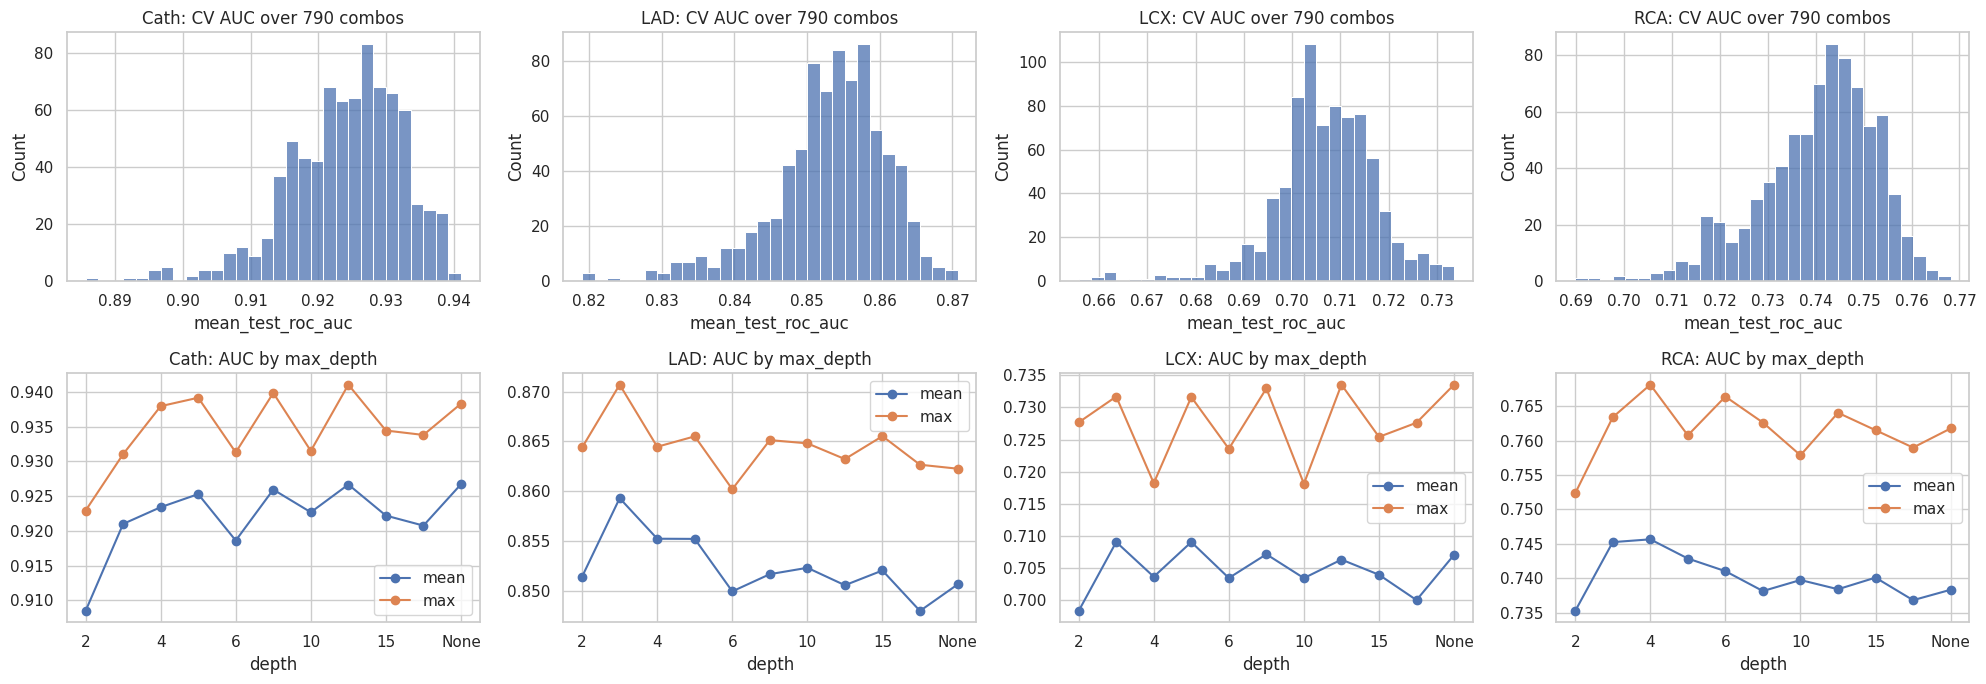

In [18]:
# distribution of CV AUC over all tried combinations + effect of depth if it was tuned
fig,axes=plt.subplots(2,4,figsize=(20,7))
for j,t in enumerate(TARGETS):
    d=pd.concat([pd.DataFrame(searches[t][n_].cv_results_) for n_ in ('grid','random')])
    sns.histplot(d.mean_test_roc_auc,bins=30,ax=axes[0,j]); axes[0,j].set_title(f'{t}: CV AUC over {len(d)} combos')
    col=[c for c in d.columns if c.endswith('max_depth')]
    if col:
        dd=d.assign(depth=d[col[0]].astype(str)).groupby('depth').mean_test_roc_auc.agg(['mean','max'])
        dd=dd.loc[sorted(dd.index,key=lambda s:(s=='None',float(s) if s not in ('None',) else 99))]
        dd.plot(ax=axes[1,j],marker='o'); axes[1,j].set_title(f'{t}: AUC by max_depth')
    else:
        d.assign(k=d['param_fs__k'].astype(str)).groupby('k').mean_test_roc_auc.max().plot.bar(ax=axes[1,j]); axes[1,j].set_title(f'{t}: best AUC by k')
plt.tight_layout(); plt.savefig(FIG/f'{M}_search_overview.png',dpi=110); plt.show()

## 9. Effect of the number of CV folds (best configuration, train only)

In [19]:
schemes={'3-fold':StratifiedKFold(3,shuffle=True,random_state=SEED),'5-fold':StratifiedKFold(5,shuffle=True,random_state=SEED),
         '7-fold':StratifiedKFold(7,shuffle=True,random_state=SEED),'10-fold':StratifiedKFold(10,shuffle=True,random_state=SEED),
         '5x3 repeated':RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED),'10x3 repeated':RepeatedStratifiedKFold(n_splits=10,n_repeats=3,random_state=SEED)}
rows=[]
for t in TARGETS:
    for nm,cv in schemes.items():
        s=cross_validate(clone(best_est[t]),X_tr,Y_tr[t],cv=cv,scoring={'auc':'roc_auc','acc':'accuracy','bal':'balanced_accuracy'},n_jobs=-1)
        rows.append({'target':t,'cv':nm,'auc_mean':s['test_auc'].mean(),'auc_std':s['test_auc'].std(),'acc_mean':s['test_acc'].mean(),'bal_acc_mean':s['test_bal'].mean()})
fold_tbl=pd.DataFrame(rows); fold_tbl.to_csv(RES/f'{M}_cv_fold_study.csv',index=False)
fold_tbl.pivot(index='cv',columns='target',values='auc_mean').loc[list(schemes)].round(4)

target,Cath,LAD,LCX,RCA
cv,,,,
3-fold,0.9351,0.8404,0.6805,0.7462
5-fold,0.9354,0.8752,0.7378,0.7606
7-fold,0.9343,0.8621,0.7132,0.7806
10-fold,0.9463,0.8573,0.7165,0.7794
5x3 repeated,0.9362,0.8667,0.7309,0.7576
10x3 repeated,0.9374,0.8637,0.7313,0.7664


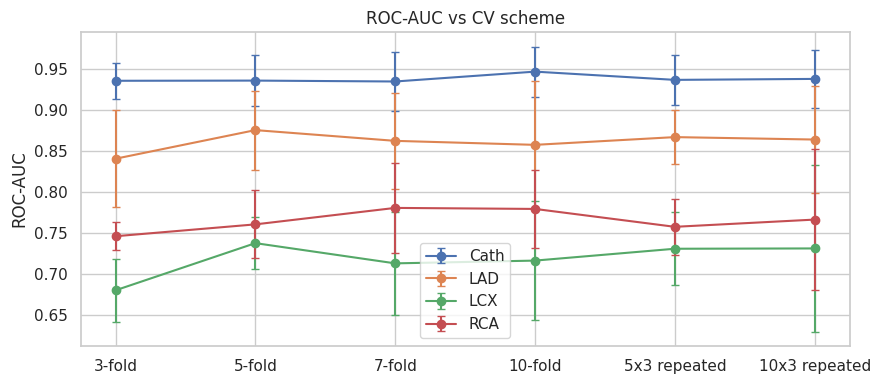

In [20]:
fig,ax=plt.subplots(figsize=(9,4))
for t in TARGETS:
    d=fold_tbl[fold_tbl.target==t]; ax.errorbar(range(len(d)),d.auc_mean,d.auc_std,marker='o',label=t,capsize=3)
ax.set_xticks(range(len(schemes))); ax.set_xticklabels(list(schemes)); ax.set_ylabel('ROC-AUC'); ax.legend(); ax.set_title('ROC-AUC vs CV scheme'); plt.tight_layout(); plt.show()

## 10. Nested CV on all 303 patients (paper-comparable protocol)
The paper reports 10-fold CV on all data. Here every outer fold tunes hyper-parameters (feature count, sampler, model parameters) on its own training part only, so the numbers are not tuned on the fold that scores them. Threshold = 0.5.

In [21]:
spec_scorer=make_scorer(recall_score,pos_label=0)
NEST_SCORING={'accuracy':'accuracy','balanced_acc':'balanced_accuracy','sensitivity':'recall','specificity':spec_scorer,'precision':'precision','f1':'f1','roc_auc':'roc_auc'}
outer=StratifiedKFold(10,shuffle=True,random_state=SEED); nested_rows=[]
for t in TARGETS:
    t0=time.time()
    inner=RandomizedSearchCV(make_pipe(new_clf()),param_space(spw[t]),n_iter=20,scoring='roc_auc',cv=StratifiedKFold(3,shuffle=True,random_state=SEED),n_jobs=1,random_state=SEED)
    r=cross_validate(inner,X_all,Y_all[t],cv=outer,scoring=NEST_SCORING,n_jobs=-1)
    row={'target':t}; row.update({k.replace('test_',''):r[k].mean() for k in r if k.startswith('test_')}); row.update({k.replace('test_','')+'_std':r[k].std() for k in r if k.startswith('test_')})
    nested_rows.append(row); print(t,f"acc={row['accuracy']:.3f} sens={row['sensitivity']:.3f} spec={row['specificity']:.3f} auc={row['roc_auc']:.3f} ({time.time()-t0:.0f}s)")
nested=pd.DataFrame(nested_rows).set_index('target'); nested.to_csv(RES/f'{M}_nested_cv.csv'); nested[[c for c in nested if not c.endswith('_std')]].round(4)

Cath acc=0.872 sens=0.903 spec=0.793 auc=0.928 (25s)


LAD acc=0.776 sens=0.847 spec=0.676 auc=0.836 (25s)


LCX acc=0.667 sens=0.498 spec=0.777 auc=0.723 (26s)


RCA acc=0.650 sens=0.553 spec=0.711 auc=0.715 (26s)


,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc
target,,,,,,,
Cath,0.8716,0.8480,0.9030,0.7931,0.9204,0.9096,0.9275
LAD,0.7761,0.7613,0.8471,0.6756,0.7868,0.8138,0.8360
LCX,0.6670,0.6375,0.4977,0.7772,0.6058,0.5268,0.7228
RCA,0.6498,0.6318,0.5530,0.7105,0.5648,0.5342,0.7147


## 11. Decision threshold from out-of-fold *train* probabilities

In [22]:
def oof_proba(est,X,y,seeds=(0,1,2)):
    P=np.zeros(len(y))
    for s in seeds: P+=cross_val_predict(clone(est),X,y,cv=StratifiedKFold(5,shuffle=True,random_state=s),method='predict_proba',n_jobs=-1)[:,1]
    return P/len(seeds)
oof={t:oof_proba(best_est[t],X_tr,Y_tr[t]) for t in TARGETS}
THR={t:{'default_0.5':0.5,'youden':thr_youden(Y_tr[t],oof[t]),'sens>=0.95':thr_sens(Y_tr[t],oof[t],0.95)} for t in TARGETS}
pd.DataFrame(THR).T.round(3)

,default_0.5,youden,sens>=0.95
Cath,0.5,0.733,0.417
LAD,0.5,0.527,0.352
LCX,0.5,0.344,0.256
RCA,0.5,0.429,0.291


In [23]:
pd.DataFrame({(t,k):metrics_at(Y_tr[t],oof[t],v) for t in TARGETS for k,v in THR[t].items()}).T[['threshold','accuracy','sensitivity','specificity','roc_auc']].round(3)

threshold  accuracy  sensitivity  specificity  roc_auc
Cath default_0.5      0.500     0.872        0.925        0.739    0.934
     youden           0.733     0.847        0.815        0.928    0.934
     sens>=0.95       0.417     0.876        0.960        0.667    0.934
LAD  default_0.5      0.500     0.777        0.844        0.683    0.859
     youden           0.527     0.785        0.816        0.743    0.859
     sens>=0.95       0.352     0.769        0.957        0.505    0.859
LCX  default_0.5      0.500     0.665        0.309        0.892    0.739
     youden           0.344     0.669        0.862        0.547    0.739
     sens>=0.95       0.256     0.562        0.968        0.304    0.739
RCA  default_0.5      0.500     0.669        0.659        0.675    0.749
     youden           0.429     0.682        0.868        0.570    0.749
     sens>=0.95       0.291     0.574        0.967        0.338    0.749

## 12. Final evaluation on the held-out test set (touched once)

In [24]:
test_proba={}
for t in TARGETS:
    best_est[t].fit(X_tr,Y_tr[t]); test_proba[t]=best_est[t].predict_proba(X_te)[:,1]
rows=[]
for t in TARGETS:
    for k,thr in THR[t].items():
        m=metrics_at(Y_te[t],test_proba[t],thr); (alo,ahi),(clo,chi)=boot_ci(Y_te[t],test_proba[t],thr)
        rows.append({'target':t,'strategy':'direct','threshold_rule':k,**m,'auc_ci':f'[{alo:.3f},{ahi:.3f}]','acc_ci':f'[{clo:.3f},{chi:.3f}]'})
test_tbl=pd.DataFrame(rows); test_tbl.to_csv(RES/f'{M}_test_metrics_direct.csv',index=False)
test_tbl[['target','threshold_rule','threshold','accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc','brier','auc_ci','acc_ci']].round(3)

,target,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,auc_ci,acc_ci
0,Cath,default_0.5,0.500,0.869,0.819,0.932,0.706,0.891,0.911,0.917,0.967,0.104,"[0.829,0.984]","[0.770,0.951]"
1,Cath,youden,0.733,0.869,0.873,0.864,0.882,0.950,0.905,0.917,0.967,0.104,"[0.829,0.984]","[0.770,0.951]"
2,Cath,sens>=0.95,0.417,0.836,0.760,0.932,0.588,0.854,0.891,0.917,0.967,0.104,"[0.829,0.984]","[0.738,0.918]"
3,LAD,default_0.5,0.500,0.770,0.757,0.833,0.680,0.789,0.811,0.827,0.877,0.169,"[0.713,0.924]","[0.656,0.869]"
4,LAD,youden,0.527,0.754,0.749,0.778,0.720,0.800,0.789,0.827,0.877,0.169,"[0.713,0.924]","[0.639,0.852]"
5,LAD,sens>=0.95,0.352,0.721,0.666,0.972,0.360,0.686,0.805,0.827,0.877,0.169,"[0.713,0.924]","[0.623,0.836]"
6,LCX,default_0.5,0.500,0.672,0.649,0.520,0.778,0.619,0.565,0.753,0.659,0.201,"[0.626,0.860]","[0.557,0.787]"
7,LCX,youden,0.344,0.656,0.690,0.880,0.500,0.550,0.677,0.753,0.659,0.201,"[0.626,0.860]","[0.525,0.770]"
8,LCX,sens>=0.95,0.256,0.574,0.633,0.960,0.306,0.490,0.649,0.753,0.659,0.201,"[0.626,0.860]","[0.459,0.705]"
9,RCA,default_0.5,0.500,0.574,0.589,0.652,0.526,0.455,0.536,0.632,0.572,0.231,"[0.489,0.770]","[0.443,0.689]"


In [25]:
# majority-class reference on the same test set
pd.DataFrame({t:{'majority-class accuracy':max(Y_te[t].mean(),1-Y_te[t].mean()),'model accuracy (youden)':test_tbl[(test_tbl.target==t)&(test_tbl.threshold_rule=='youden')].accuracy.iloc[0]} for t in TARGETS}).T.round(3)

,majority-class accuracy,model accuracy (youden)
Cath,0.721,0.869
LAD,0.590,0.754
LCX,0.590,0.656
RCA,0.623,0.557


## 13. Curves and confusion matrices

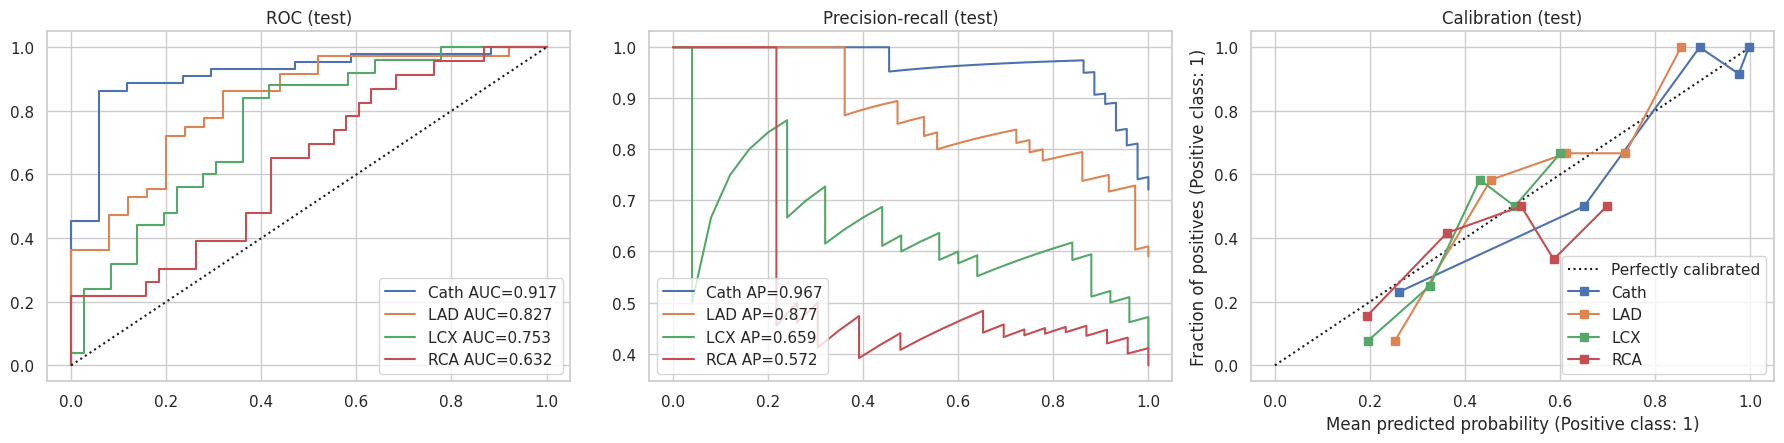

In [26]:
fig,axes=plt.subplots(1,3,figsize=(18,4.6))
for t in TARGETS:
    f,s,_=roc_curve(Y_te[t],test_proba[t]); axes[0].plot(f,s,label=f'{t} AUC={roc_auc_score(Y_te[t],test_proba[t]):.3f}')
    p,r,_=precision_recall_curve(Y_te[t],test_proba[t]); axes[1].plot(r,p,label=f'{t} AP={average_precision_score(Y_te[t],test_proba[t]):.3f}')
    CalibrationDisplay.from_predictions(Y_te[t],test_proba[t],n_bins=5,strategy='quantile',ax=axes[2],name=t)
axes[0].plot([0,1],[0,1],'k:'); axes[0].set_title('ROC (test)'); axes[1].set_title('Precision-recall (test)'); axes[2].set_title('Calibration (test)')
for a in axes[:2]: a.legend()
plt.tight_layout(); plt.savefig(FIG/f'{M}_curves.png',dpi=110); plt.show()

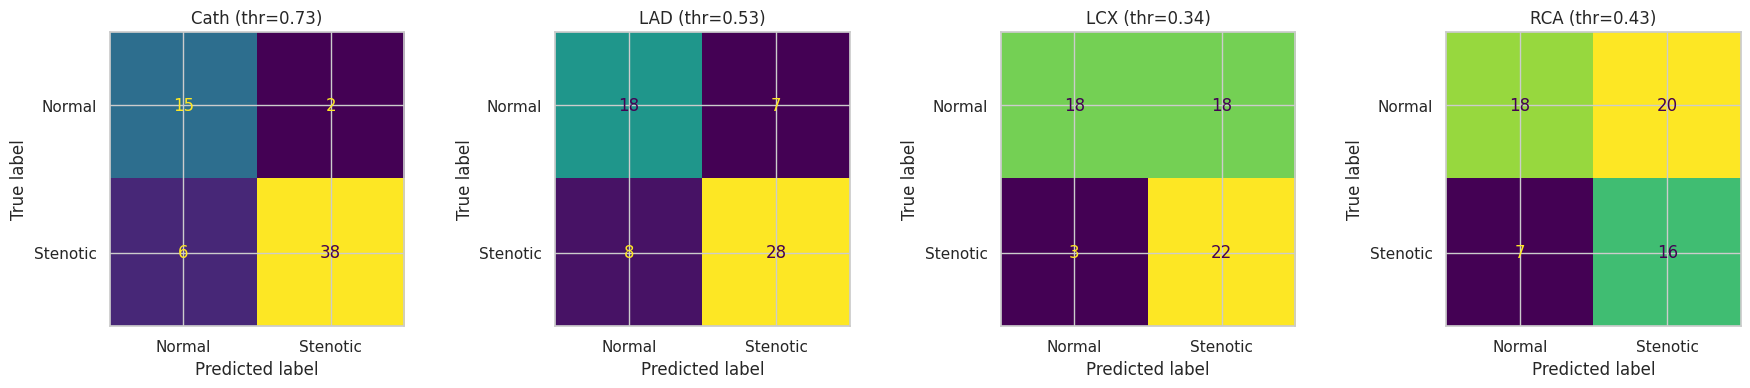

In [27]:
fig,axes=plt.subplots(1,4,figsize=(18,4))
for ax,t in zip(axes,TARGETS):
    thr=THR[t]['youden']; ConfusionMatrixDisplay.from_predictions(Y_te[t],(test_proba[t]>=thr).astype(int),ax=ax,colorbar=False,display_labels=['Normal','Stenotic']); ax.set_title(f'{t} (thr={thr:.2f})')
plt.tight_layout(); plt.savefig(FIG/f'{M}_confusion.png',dpi=110); plt.show()

## 14. Paper methods on this model family
1. **Single classifier** – Cath model only (section 12).
2. **Three-classifier OR rule** – `CT = LAD ∨ LCX ∨ RCA` (Eq. 1 of the paper).
3. **Feature-engineering (stacked) method** – out-of-fold probabilities of the LAD/LCX/RCA/CAD models are appended to the clinical features and a final CAD classifier is trained on them. Train probabilities are out-of-fold, test probabilities come from models fitted on the full train set.

In [28]:
# 2) OR rule
rows=[]
for rule in ('default_0.5','youden'):
    pred=np.zeros(len(te),int)
    for t in ['LAD','LCX','RCA']: pred|=(test_proba[t]>=THR[t][rule]).astype(int)
    score=1-np.prod([1-test_proba[t] for t in ['LAD','LCX','RCA']],axis=0)               # P(at least one stenotic), independence assumption
    yh=pred; tn,fp,fn,tp=confusion_matrix(Y_te['Cath'],yh,labels=[0,1]).ravel()
    rows.append({'target':'Cath','strategy':'OR-rule','threshold_rule':rule,'accuracy':accuracy_score(Y_te['Cath'],yh),'balanced_acc':balanced_accuracy_score(Y_te['Cath'],yh),
                 'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),'precision':precision_score(Y_te['Cath'],yh,zero_division=0),'f1':f1_score(Y_te['Cath'],yh),
                 'roc_auc':roc_auc_score(Y_te['Cath'],score),'pr_auc':average_precision_score(Y_te['Cath'],score),'brier':brier_score_loss(Y_te['Cath'],score),'TP':tp,'FP':fp,'TN':tn,'FN':fn})
or_tbl=pd.DataFrame(rows); or_tbl.round(3)

,target,strategy,threshold_rule,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,TP,FP,TN,FN
0,Cath,OR-rule,default_0.5,0.82,0.803,0.841,0.765,0.902,0.871,0.913,0.963,0.133,37,4,13,7
1,Cath,OR-rule,youden,0.82,0.767,0.886,0.647,0.867,0.876,0.913,0.963,0.133,39,6,11,5


In [29]:
# 3) stacked method
PCOLS=['p_LAD','p_LCX','p_RCA','p_CAD']
oof_tr={t:cross_val_predict(clone(best_est[t]),X_tr,Y_tr[t],cv=StratifiedKFold(5,shuffle=True,random_state=SEED),method='predict_proba',n_jobs=-1)[:,1] for t in TARGETS}
def augment(X,P):
    A=X.copy()
    for c,t in zip(PCOLS,['LAD','LCX','RCA','Cath']): A[c]=P[t]
    return A
Xa_tr=augment(X_tr,oof_tr); Xa_te=augment(X_te,test_proba)
def meta_pipe():
    p=clone(best_est['Cath']); p.set_params(prep=ColumnTransformer([('base',build_preprocessor(),FEATURES),('probs','passthrough',PCOLS)],verbose_feature_names_out=False))
    return p
mg=GridSearchCV(meta_pipe(),{'fs__k':[4,8,12,20,32,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)]},scoring='roc_auc',cv=cv52,n_jobs=-1).fit(Xa_tr,Y_tr['Cath'])
meta=mg.best_estimator_; print('stacked CV AUC:',round(mg.best_score_,4),'| params:',{k:v for k,v in mg.best_params_.items()})
oof_meta=oof_proba(meta,Xa_tr,Y_tr['Cath']); thr_meta={'default_0.5':0.5,'youden':thr_youden(Y_tr['Cath'],oof_meta),'sens>=0.95':thr_sens(Y_tr['Cath'],oof_meta,0.95)}
meta.fit(Xa_tr,Y_tr['Cath']); p_meta=meta.predict_proba(Xa_te)[:,1]
st=pd.DataFrame([{'target':'Cath','strategy':'stacked (paper FE)','threshold_rule':k,**metrics_at(Y_te['Cath'],p_meta,v)} for k,v in thr_meta.items()]); st.round(3)

stacked CV AUC: 0.9383 | params: {'fs__k': 32, 'sampler': SMOTE(random_state=42)}


,target,strategy,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,TP,FP,TN,FN
0,Cath,stacked (paper FE),default_0.5,0.500,0.869,0.837,0.909,0.765,0.909,0.909,0.926,0.973,0.1,40,4,13,4
1,Cath,stacked (paper FE),youden,0.663,0.885,0.866,0.909,0.824,0.930,0.920,0.926,0.973,0.1,40,3,14,4
2,Cath,stacked (paper FE),sens>=0.95,0.254,0.852,0.753,0.977,0.529,0.843,0.905,0.926,0.973,0.1,43,8,9,1


In [30]:
# compare the three strategies for CAD with the paper's SVM numbers (10-fold CV on 500 patients; ours: held-out test of 61)
paper=pd.DataFrame([{'strategy':'PAPER single (SVM)','accuracy':.850,'sensitivity':.894,'specificity':.768,'roc_auc':.81},
                    {'strategy':'PAPER three-classifier (SVM)','accuracy':.810,'sensitivity':.814,'specificity':.798,'roc_auc':.87},
                    {'strategy':'PAPER feature engineering (SVM)','accuracy':.964,'sensitivity':1.0,'specificity':.881,'roc_auc':.92}])
ours=pd.concat([test_tbl[test_tbl.target=='Cath'].assign(strategy=lambda d:'direct @'+d.threshold_rule),or_tbl.assign(strategy=lambda d:'OR-rule @'+d.threshold_rule),
                st.assign(strategy=lambda d:'stacked @'+d.threshold_rule)])[['strategy','accuracy','sensitivity','specificity','roc_auc']]
cmp_tbl=pd.concat([paper,ours.assign(strategy=lambda d:'OURS '+M+' '+d.strategy)]).set_index('strategy'); cmp_tbl.round(3)

,accuracy,sensitivity,specificity,roc_auc
strategy,,,,
PAPER single (SVM),0.850,0.894,0.768,0.810
PAPER three-classifier (SVM),0.810,0.814,0.798,0.870
PAPER feature engineering (SVM),0.964,1.000,0.881,0.920
OURS rf direct @default_0.5,0.869,0.932,0.706,0.917
OURS rf direct @youden,0.869,0.864,0.882,0.917
OURS rf direct @sens>=0.95,0.836,0.932,0.588,0.917
OURS rf OR-rule @default_0.5,0.820,0.841,0.765,0.913
OURS rf OR-rule @youden,0.820,0.886,0.647,0.913
OURS rf stacked @default_0.5,0.869,0.909,0.765,0.926


In [31]:
all_rows=pd.concat([test_tbl,or_tbl,st]); all_rows.to_csv(RES/f'{M}_test_metrics.csv',index=False)
nested.loc[['Cath']].round(3).rename(index={'Cath':'OURS nested 10-fold CV (303 pts, thr 0.5)'})[['accuracy','sensitivity','specificity','roc_auc']]

,accuracy,sensitivity,specificity,roc_auc
target,,,,
"OURS nested 10-fold CV (303 pts, thr 0.5)",0.872,0.903,0.793,0.928


## 15. Permutation importance on the test set (raw features, per target)

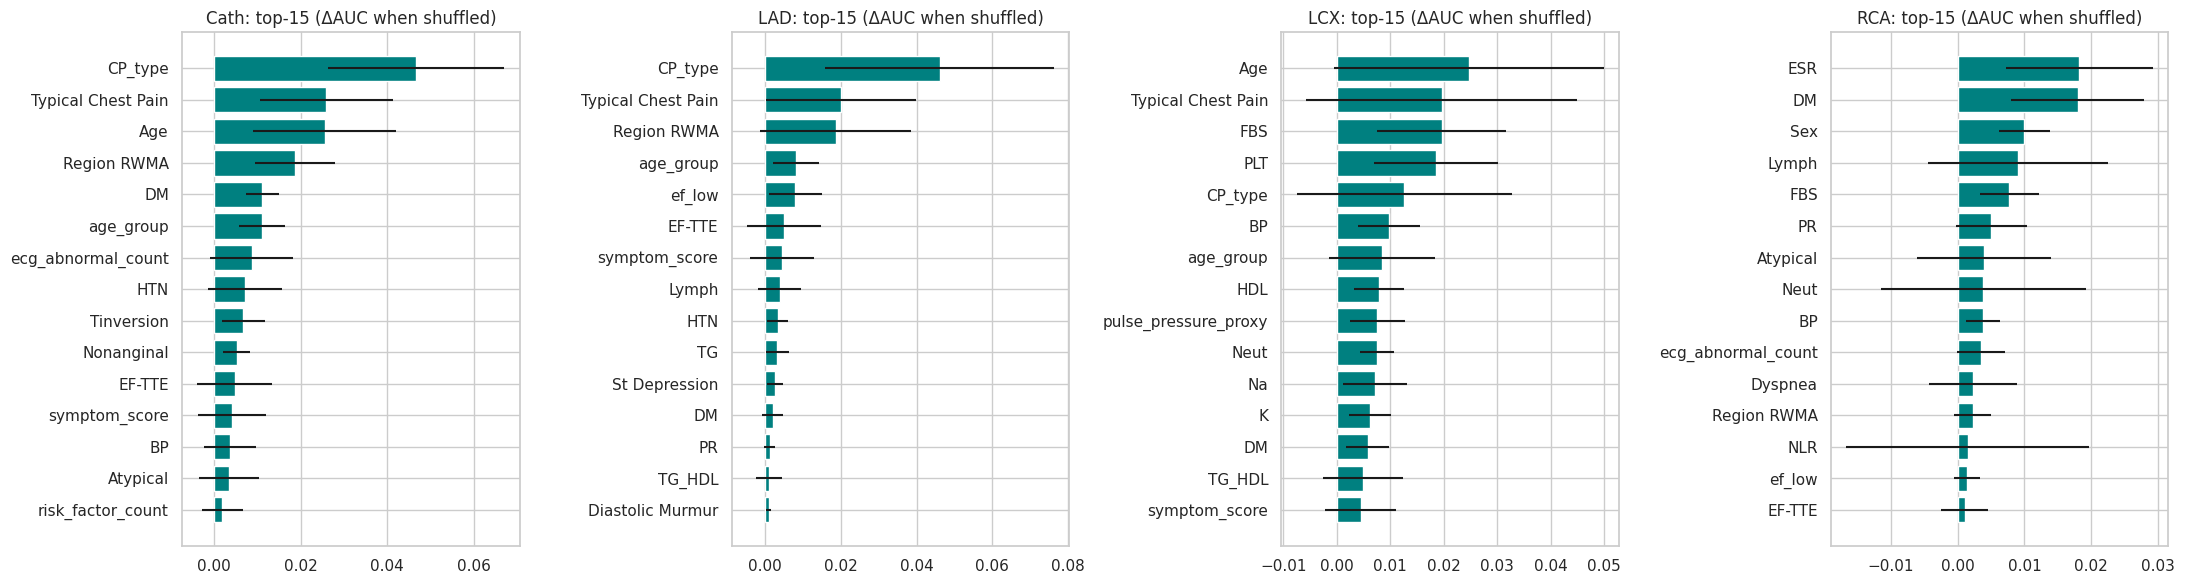

In [32]:
imp={}
for t in TARGETS:
    r=permutation_importance(best_est[t],X_te,Y_te[t],scoring='roc_auc',n_repeats=30,random_state=SEED,n_jobs=-1)
    imp[t]=pd.DataFrame({'importance':r.importances_mean,'std':r.importances_std},index=FEATURES).sort_values('importance',ascending=False)
    imp[t].to_csv(RES/f'{M}_perm_importance_{t}.csv')
fig,axes=plt.subplots(1,4,figsize=(22,6))
for ax,t in zip(axes,TARGETS):
    d=imp[t].head(15)[::-1]; ax.barh(d.index,d.importance,xerr=d['std'],color='teal'); ax.set_title(f'{t}: top-15 (ΔAUC when shuffled)')
plt.tight_layout(); plt.savefig(FIG/f'{M}_perm_importance.png',dpi=110); plt.show()

In [33]:
pd.concat({t:imp[t].head(10).importance.round(4).reset_index().rename(columns={'index':'feature'}) for t in TARGETS},axis=1)

Cath                            LAD                              LCX                            RCA           
              feature importance             feature importance               feature importance             feature importance
0             CP_type     0.0467             CP_type     0.0461                   Age     0.0247                 ESR     0.0182
1  Typical Chest Pain     0.0259  Typical Chest Pain     0.0201    Typical Chest Pain     0.0197                  DM     0.0180
2                 Age     0.0255         Region RWMA     0.0187                   FBS     0.0196                 Sex     0.0100
3         Region RWMA     0.0186           age_group     0.0081                   PLT     0.0186               Lymph     0.0090
4                  DM     0.0111              ef_low     0.0080               CP_type     0.0127                 FBS     0.0077
5           age_group     0.0111              EF-TTE     0.0050                    BP     0.0098                  PR     0.0050
6  ecg_abnormal_count     0.0086       symptom_score     0.0045             age_group     0.0085            Atypical     0.0039
7                 HTN     0.0071               Lymph     0.0039                   HDL     0.0080                Neut     0.0038
8          Tinversion     0.0068                 HTN     0.0033  pulse_pressure_proxy     0.0076                  BP     0.0038
9          Nonanginal     0.0052                  TG     0.0033                  Neut     0.0075  ecg_abnormal_count     0.0035

## 16. Save fitted pipelines and probabilities

In [34]:
for t in TARGETS: joblib.dump(best_est[t],MOD/f'{M}_{t}.joblib')
joblib.dump(meta,MOD/f'{M}_stacked_Cath.joblib')
pd.DataFrame({t:test_proba[t] for t in TARGETS}|{'stacked_Cath':p_meta,'patient_idx':te.patient_idx.values}).to_csv(RES/f'{M}_test_proba.csv',index=False)
pd.DataFrame({t:oof[t] for t in TARGETS}|{'patient_idx':tr.patient_idx.values}).to_csv(RES/f'{M}_oof_train_proba.csv',index=False)
best_tbl.to_csv(RES/f'{M}_best_cv_summary.csv'); best_params.to_csv(RES/f'{M}_best_params.csv'); baseline.to_csv(RES/f'{M}_baseline.csv')
print('saved:',sorted(p.name for p in RES.glob(f'{M}_*'))[:30])

saved: ['rf_baseline.csv', 'rf_best_cv_summary.csv', 'rf_best_params.csv', 'rf_cv_fold_study.csv', 'rf_cv_grid_Cath.csv', 'rf_cv_grid_LAD.csv', 'rf_cv_grid_LCX.csv', 'rf_cv_grid_RCA.csv', 'rf_cv_random_Cath.csv', 'rf_cv_random_LAD.csv', 'rf_cv_random_LCX.csv', 'rf_cv_random_RCA.csv', 'rf_nested_cv.csv', 'rf_oof_train_proba.csv', 'rf_perm_importance_Cath.csv', 'rf_perm_importance_LAD.csv', 'rf_perm_importance_LCX.csv', 'rf_perm_importance_RCA.csv', 'rf_test_metrics.csv', 'rf_test_metrics_direct.csv', 'rf_test_proba.csv']


## 17. Summary

In [35]:
summary=test_tbl[test_tbl.threshold_rule=='youden'].set_index('target')[['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].round(3)
summary.loc['Cath (stacked)']=st[st.threshold_rule=='youden'][['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].iloc[0].round(3)
summary

,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc
target,,,,,,,,
Cath,0.869,0.873,0.864,0.882,0.950,0.905,0.917,0.967
LAD,0.754,0.749,0.778,0.720,0.800,0.789,0.827,0.877
LCX,0.656,0.690,0.880,0.500,0.550,0.677,0.753,0.659
RCA,0.557,0.585,0.696,0.474,0.444,0.542,0.632,0.572
Cath (stacked),0.885,0.866,0.909,0.824,0.930,0.920,0.926,0.973
